<a href="https://colab.research.google.com/github/erickcorrea3092/Cheminformatics-course/blob/main/4_7_molplotly.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trazado de coordenadas 3D

Este cuaderno contiene un ejemplo de uso de «molplotly» para trazar las posiciones de diferentes ligandos acoplados.

Carguemos algunos ligandos acoplados y grafiquemos las poses.


In [1]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
a= True
if a== True:
  with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      ! pip install dash==3.2.0
      pbar.update(25)
      ! pip install rdkit
      pbar.update(25)
      ! pip install molplotly
      pbar.update(25)
      ! gdown --id 1nOZsCcqS0blwXMbxtWEveFw32voybrwk
      pbar.update(25)

  0%|          | 0/100 [00:00<?, ?it/s]

In [2]:
import pandas as pd
import plotly.express as px
import molplotly
from rdkit import Chem
from rdkit.Chem import Draw

In [3]:
#Carga las poses de los ligandos
poses=Chem.SDMolSupplier('ligand_poses.sdf')
renamed_poses=[]


/usr/local/lib/python3.13/dist-packages/rdkit/Chem/Draw/IPythonConsole.py:376: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


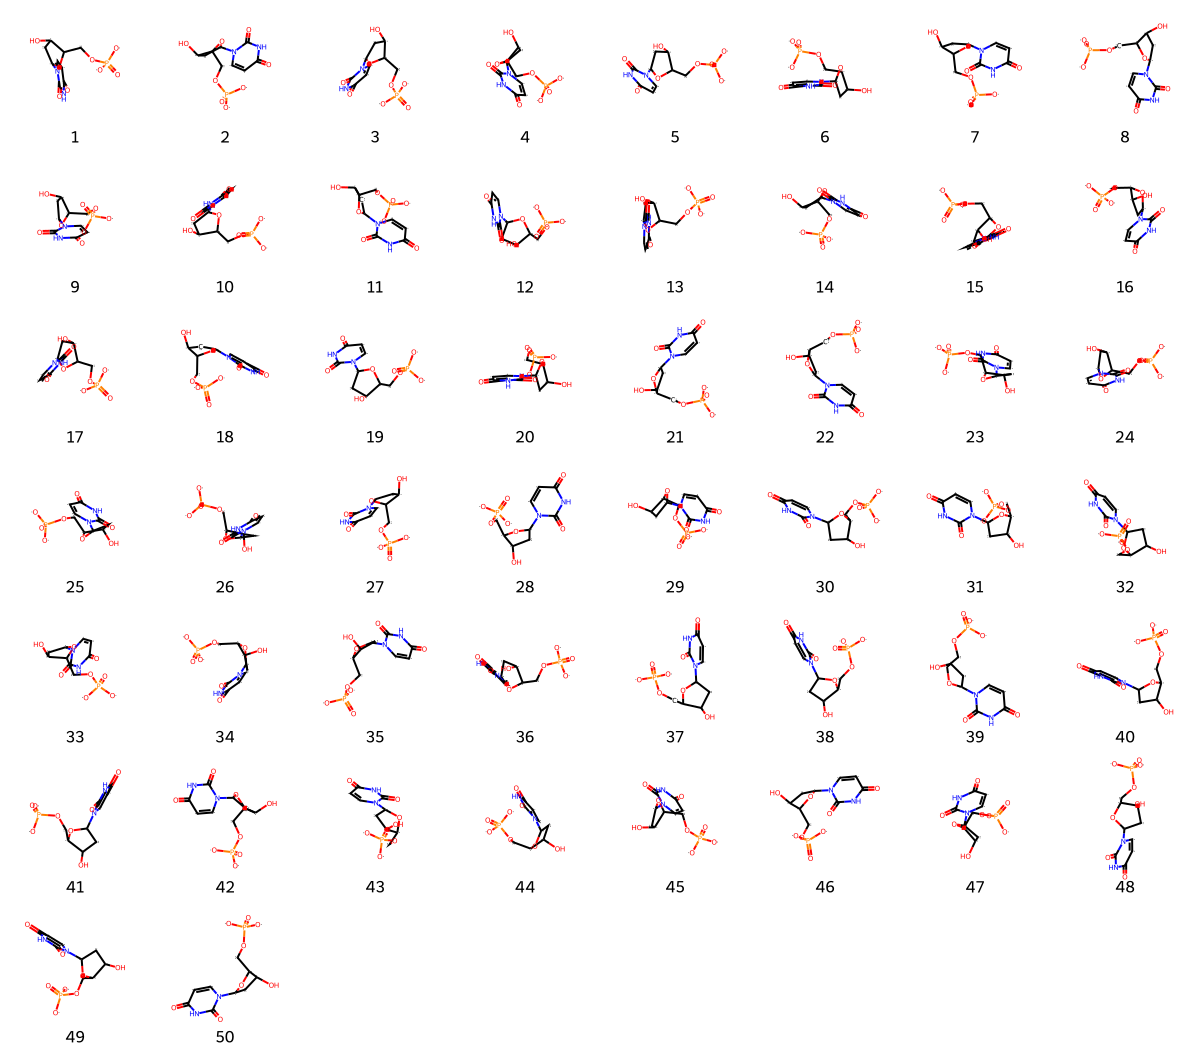

In [4]:

# Itera sobre cada molécula cargada del archivo SDF.
for index, docked_mol in enumerate(poses):
    # Asigna a cada molécula una propiedad llamada _Name con un valor numérico
    # (empezando desde '1'). Esto sirve para identificar cada pose de ligando.
    docked_mol.SetProp('_Name',str(index+1))
    # Añade la molécula renombrada a la lista renamed_poses.
    renamed_poses.append(docked_mol)


# Genera una imagen de cuadrícula de todas las moléculas en renamed_poses.
img=Draw.MolsToGridImage(renamed_poses,
                         molsPerRow=(8),
                         subImgSize=(150,150),
                         legends=[i.GetProp('_Name') for i in renamed_poses],
                         useSVG=False
                         )
img

Calculemos el RMSD por pares, después de la alineación MCS entre las poses (debería tomar alrededor de 20 segundos)

In [5]:
import numpy as np
from rdkit.Chem import rdFMCS

# Este código está diseñado para calcular la Matriz de Desviación Cuadrática Media (RMSD)
# por pares entre todas las poses de ligandos disponibles:

# crea una matriz vacía, del tamaño número_de_poses por número_de_poses,
# que se usará para almacenar los valores de RMSD.

rmsd_matrix = np.empty((len(poses), len(poses)))

#  iteran a través de todas las combinaciones posibles de las poses,
# comparando cada pose (mol) con todas las demás poses (jmol), incluyendo consigo misma.

for i, mol in enumerate(renamed_poses):
    for j, jmol in enumerate(renamed_poses):
        # Identificación MCS entre la pose de referencia y la pose del target
        r=rdFMCS.FindMCS([mol,jmol])
        # Mapa de átomos y target
        a=mol.GetSubstructMatch(Chem.MolFromSmarts(r.smartsString))
        b=jmol.GetSubstructMatch(Chem.MolFromSmarts(r.smartsString))
        # Generación de mapas de átomos
        amap=list(zip(a,b))

        # Cálculo de la distancia por par de átomos
        distances=[]
        for atomA, atomB in amap:
            pos_A=mol.GetConformer().GetAtomPosition (atomA)
            pos_B=jmol.GetConformer().GetAtomPosition (atomB)
            coord_A=np.array((pos_A.x,pos_A.y,pos_A.z))
            coord_B=np.array ((pos_B.x,pos_B.y,pos_B.z))
            dist_numpy = np.linalg.norm(coord_A-coord_B)
            distances.append(dist_numpy)

        # Esta es la fórmula RMSD de Wikipedia
        rmsd=np.sqrt(np.mean(np.square(distances)))

        # Guarda el valor de RMSD calculado en la posición correcta de la matriz.
        rmsd_matrix[i,j]=rmsd


# Convierte la matriz RMSD de NumPy en un DataFrame de Pandas, utilizando los nombres de
# las poses como índices de filas y columnas para facilitar su lectura y análisis.
rmsd_df = pd.DataFrame(rmsd_matrix,
                       index=[mol.GetProp('_Name') for mol in renamed_poses],
                       columns=[mol.GetProp('_Name') for mol in renamed_poses])

Agrupemos las poses en 5 grupos con una K-media sobre la matriz RMSD.

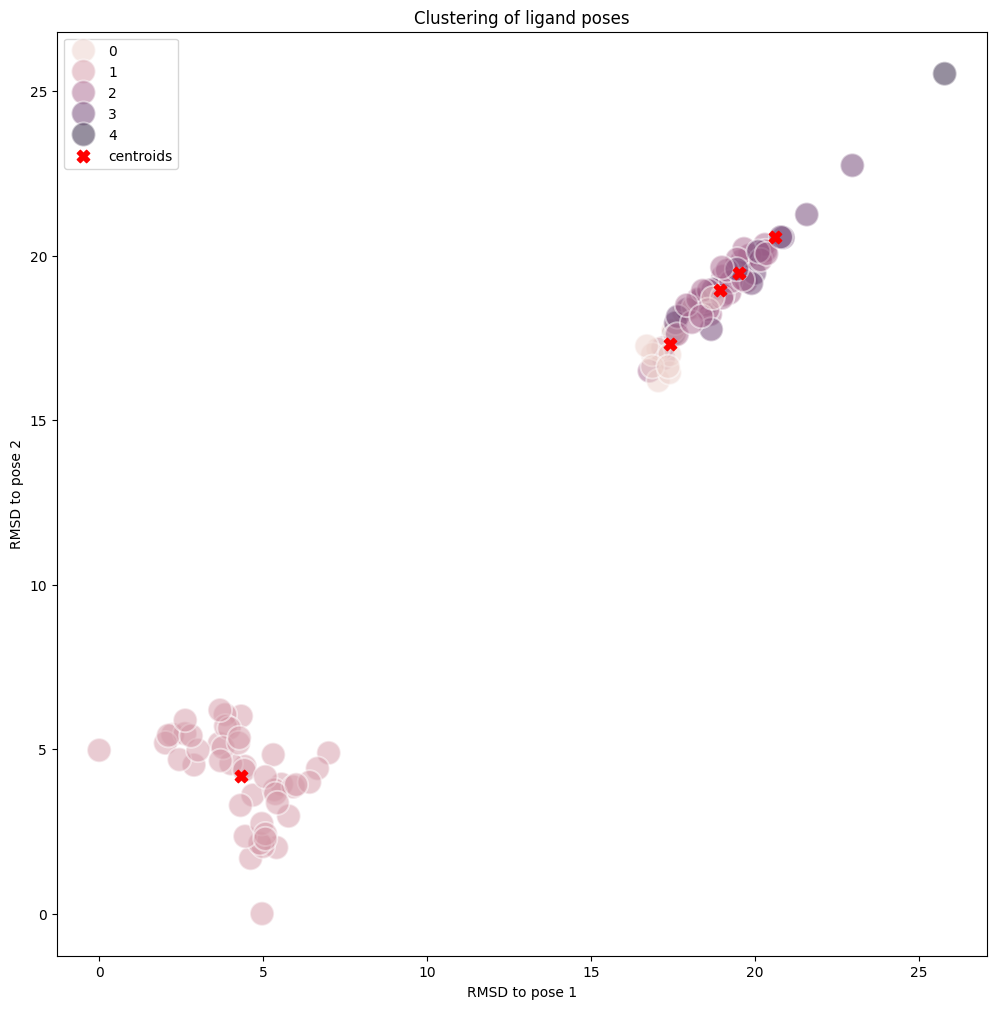

In [6]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, init='k-means++', random_state=0, ).fit(rmsd_matrix)
figure= plt.figure(figsize=(12,12))

sns.scatterplot(data=rmsd_df,
                x="1",
                y="2",
                hue=kmeans.labels_,
                alpha=0.5,
                s=300,
                )
plt.scatter(x = kmeans.cluster_centers_[:,0],
            y = kmeans.cluster_centers_[:,1],
            marker="X",
            c="r",
            s=80,
            label="centroids")
plt.title('Clustering of ligand poses')
plt.xlabel('RMSD to pose 1')
plt.ylabel('RMSD to pose 2')
plt.legend()
plt.show()

¡Haciendo lo mismo en `plotly`!

In [7]:
import plotly.graph_objects as go

rmsd_df['pose_index'] = range(1, len(renamed_poses)+1)
rmsd_df['cluster'] = kmeans.labels_
rmsd_df['cluster'] = rmsd_df['cluster'].astype(str)

scatter_fig = px.scatter(rmsd_df,
                x="1",
                y="2",
                color='cluster',
                hover_name='pose_index',
                width=1000,
                height=800,
                title='Clustering of ligand poses',
                labels={'1':'RMSD to pose 1',
                        '2':'RMSD to pose 2',}
                )
scatter_fig.add_trace(
        go.Scatter(
            x = kmeans.cluster_centers_[:,0],
            y = kmeans.cluster_centers_[:,1],
            mode='markers',
            marker=dict(color="red",
                        symbol='x',
                        size=10),
            showlegend=False,))
scatter_fig.update_traces(marker=dict(size=12))


Al añadir molplotly y especificar mol_col, se pueden mostrar las coordenadas 3D de la pose al pasar el ratón.

Desafortunadamente, existen problemas con el manejo de trazas no moleculares adicionales en molplotly, por lo que tendremos que recrear el diagrama de dispersión sin los centroides (cruces).

In [8]:
import molplotly


# Añade una nueva columna llamada 'mol' al DataFrame rmsd_df.
# Esta columna contiene los objetos RDKit Mol de las poses de ligando (renamed_poses), y,
# es crucial para que molplotly sepa qué moléculas dibujar.
rmsd_df['mol'] = renamed_poses


# Crea una figura de diagrama de dispersión inicial utilizando plotly.express
scatter_fig = px.scatter(rmsd_df,
                x="1",
                y="2",
                color='cluster',
                hover_name='pose_index',
                width=1000,
                height=800,
                title='Clustering of ligand poses',
                labels={'1':'RMSD to pose 1',
                        '2':'RMSD to pose 2',}
                )

# Ajusta el tamaño de los marcadores en el diagrama de dispersión para hacerlos más visibles.
scatter_fig.update_traces(marker=dict(size=12))


# Esta es la parte central de la integración de molplotly
app_clusters = molplotly.add_molecules(
    fig=scatter_fig,
    df=rmsd_df,
    mol_col="mol", # Observa que no parte de smiles_col
    color_col='cluster',
    title_col="pose_index",
    caption_transform={'pose_index': lambda x: f'Pose {x}'},
)

app_clusters.run(mode="inline",
                        port=8704, height=850)


/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

El uso de `smiles_mol` vuelve a la representación de moléculas 2D predeterminada

In [9]:
rmsd_df['SMILES'] = [Chem.MolToSmiles(mol) for mol in renamed_poses]

app_clusters = molplotly.add_molecules(
    fig=scatter_fig,
    df=rmsd_df,
    smiles_col="SMILES",
    color_col='cluster',
    title_col="pose_index",
    caption_transform={'pose_index': lambda x: f'Pose {x}'},
    show_coords=True,
)

app_clusters.run(#mode="inline",
                 port=8705, height=850)



/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>